# CPV301 Practical Exam - L30_PE

This notebook answers:

- Question 1: Image denoising on `exam_images/q1_beach_noise`
- Question 2: Feature matching, homography estimation, similarity matrix, and bonus stitching on `exam_images/q2_bridge_views`

The notebook is written to run from the exam folder or from the repository root.

In [1]:
from pathlib import Path
import itertools
import math
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from skimage.metrics import structural_similarity as structural_similarity
except Exception as exc:
    structural_similarity = None
    warnings.warn(f"SSIM unavailable: {exc}")

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["axes.grid"] = False
plt.rcParams["font.size"] = 10

def find_exam_root():
    here = Path.cwd().resolve()
    search_roots = [here, *here.parents]

    for base in search_roots:
        if (base / "exam_images").exists() and (base / "CPV301_Practical_Exam.md").exists():
            return base

    for base in search_roots:
        matches = sorted(base.glob("main/L30_Practical_Exam_*/exam_images"))
        matches += sorted(base.glob("L30_Practical_Exam_*/exam_images"))
        if matches:
            return matches[0].parent

    raise FileNotFoundError("Could not locate L30_Practical_Exam_* folder.")

EXAM_ROOT = find_exam_root()
DATA_DIR = EXAM_ROOT / "exam_images"
OUT_DIR = EXAM_ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

print("Exam root:", EXAM_ROOT)
print("Data dir:", DATA_DIR)
print("Output dir:", OUT_DIR)
print("OpenCV:", cv2.__version__)
print("SIFT available:", hasattr(cv2, "SIFT_create"))

Exam root: /home/dacekey/CPV301_SUM26/main/L30_Practical_Exam_*
Data dir: /home/dacekey/CPV301_SUM26/main/L30_Practical_Exam_*/exam_images
Output dir: /home/dacekey/CPV301_SUM26/main/L30_Practical_Exam_*/outputs
OpenCV: 4.13.0
SIFT available: True


In [2]:
def imread_rgb(path):
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def to_gray(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

def save_rgb(path, img_rgb):
    cv2.imwrite(str(path), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))

def metric_scores(reference_rgb, test_rgb):
    psnr = float(cv2.PSNR(reference_rgb, test_rgb))
    if structural_similarity is None:
        return psnr, np.nan
    try:
        ssim = structural_similarity(reference_rgb, test_rgb, channel_axis=2, data_range=255)
    except TypeError:
        ssim = structural_similarity(reference_rgb, test_rgb, multichannel=True, data_range=255)
    return psnr, float(ssim)

def show_images(images, titles, cols=3, figsize=(14, 8), save_path=None):
    rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()

## Question 1 - Image Denoising

The clean reference image is used only for quantitative evaluation. Noise identification is based on visual appearance, grayscale histograms, and residual statistics against the provided clean image.

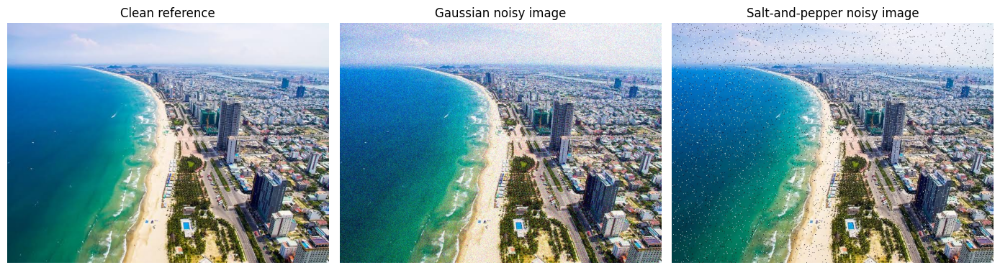

In [3]:
q1_dir = DATA_DIR / "q1_beach_noise"

clean = imread_rgb(q1_dir / "my_khe.jpeg")
gaussian_noisy = imread_rgb(q1_dir / "my_khe_gaussian_noise.jpg")
saltpepper_noisy = imread_rgb(q1_dir / "my_khe_saltpepper_noise.jpg")

show_images(
    [clean, gaussian_noisy, saltpepper_noisy],
    ["Clean reference", "Gaussian noisy image", "Salt-and-pepper noisy image"],
    cols=3,
    figsize=(14, 5),
    save_path=OUT_DIR / "q1_input_images.png",
)

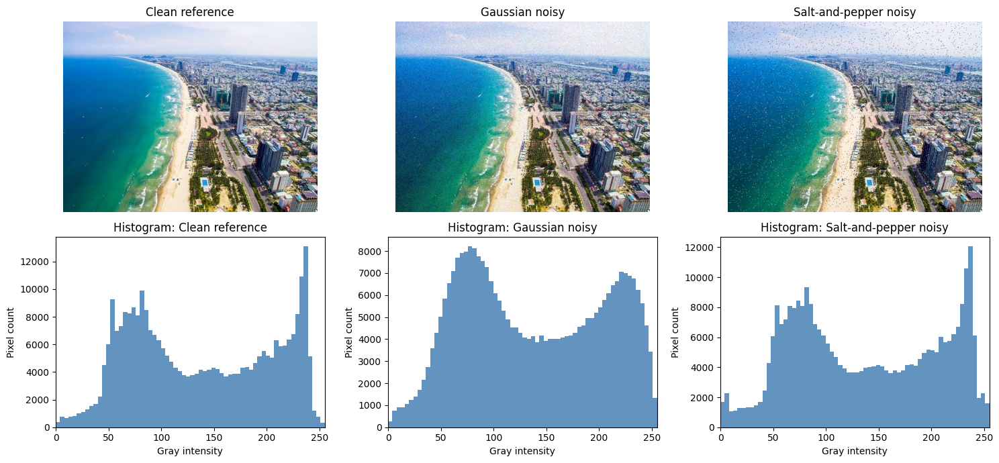

,image,identified_noise,extreme_pixel_%_(gray<5_or_>250),residual_mean,residual_std,large_residual_%_(abs>50)
0,my_khe_gaussian_noise.jpg,Gaussian noise,0.842,-0.086,13.836,0.029
1,my_khe_saltpepper_noise.jpg,Salt-and-pepper noise,1.611,-0.355,23.983,2.354


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
q1_images = [
    ("Clean reference", clean),
    ("Gaussian noisy", gaussian_noisy),
    ("Salt-and-pepper noisy", saltpepper_noisy),
]

for ax, (title, img) in zip(axes[0], q1_images):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

for ax, (title, img) in zip(axes[1], q1_images):
    g = to_gray(img)
    ax.hist(g.ravel(), bins=64, range=(0, 255), color="steelblue", alpha=0.85)
    ax.set_title(f"Histogram: {title}")
    ax.set_xlim(0, 255)
    ax.set_xlabel("Gray intensity")
    ax.set_ylabel("Pixel count")

plt.tight_layout()
fig.savefig(OUT_DIR / "q1_noise_histograms.png", dpi=160, bbox_inches="tight")
plt.show()

noise_rows = []
for label, img, conclusion in [
    ("my_khe_gaussian_noise.jpg", gaussian_noisy, "Gaussian noise"),
    ("my_khe_saltpepper_noise.jpg", saltpepper_noisy, "Salt-and-pepper noise"),
]:
    gray = to_gray(img)
    residual = img.astype(np.int16) - clean.astype(np.int16)
    noise_rows.append(
        {
            "image": label,
            "identified_noise": conclusion,
            "extreme_pixel_%_(gray<5_or_>250)": 100.0 * np.mean((gray < 5) | (gray > 250)),
            "residual_mean": residual.mean(),
            "residual_std": residual.std(),
            "large_residual_%_(abs>50)": 100.0 * np.mean(np.abs(residual) > 50),
        }
    )

noise_df = pd.DataFrame(noise_rows)
display(noise_df.round(3))

**Noise identification.** `my_khe_gaussian_noise.jpg` shows fine, continuous grain spread across the image. Its residuals are centered close to zero, which is consistent with additive Gaussian noise. `my_khe_saltpepper_noise.jpg` contains isolated dark/bright impulses and a larger percentage of extreme pixels and large residuals, which is typical salt-and-pepper noise.

In [5]:
# Denoising choices:
# - Gaussian noise: Gaussian blur is required by the task; sigma=0.5 reduces noise while limiting blur.
# - Salt-and-pepper noise: median filtering is the standard choice because it removes isolated impulses.
# - Bilateral filtering is applied to the Gaussian-noisy image to compare edge preservation.

gaussian_blur = cv2.GaussianBlur(gaussian_noisy, (3, 3), 0.5)
gaussian_bilateral = cv2.bilateralFilter(gaussian_noisy, d=9, sigmaColor=75, sigmaSpace=75)

sp_median = cv2.medianBlur(saltpepper_noisy, 3)
sp_gaussian_for_compare = cv2.GaussianBlur(saltpepper_noisy, (3, 3), 0.5)
sp_bilateral_for_compare = cv2.bilateralFilter(saltpepper_noisy, d=9, sigmaColor=75, sigmaSpace=75)

q1_results = [
    ("Gaussian noise", "Noisy input", gaussian_noisy),
    ("Gaussian noise", "Gaussian blur 3x3 sigma=0.5", gaussian_blur),
    ("Gaussian noise", "Bilateral d=9 sc=75 ss=75", gaussian_bilateral),
    ("Salt-and-pepper noise", "Noisy input", saltpepper_noisy),
    ("Salt-and-pepper noise", "Median filter 3x3", sp_median),
    ("Salt-and-pepper noise", "Gaussian blur 3x3 sigma=0.5", sp_gaussian_for_compare),
    ("Salt-and-pepper noise", "Bilateral d=9 sc=75 ss=75", sp_bilateral_for_compare),
]

metric_rows = []
for noise_type, method, img in q1_results:
    psnr, ssim = metric_scores(clean, img)
    metric_rows.append(
        {
            "noise_type": noise_type,
            "method": method,
            "PSNR_dB": psnr,
            "SSIM": ssim,
        }
    )

q1_metric_df = pd.DataFrame(metric_rows)
q1_metric_df.to_csv(OUT_DIR / "q1_psnr_ssim.csv", index=False)
display(q1_metric_df.round(4))

best_by_ssim = q1_metric_df.loc[
    q1_metric_df.groupby("noise_type")["SSIM"].idxmax(),
    ["noise_type", "method", "PSNR_dB", "SSIM"],
].reset_index(drop=True)
print("Best method per noise type by SSIM:")
display(best_by_ssim.round(4))

,noise_type,method,PSNR_dB,SSIM
0,Gaussian noise,Noisy input,25.3105,0.5835
1,Gaussian noise,Gaussian blur 3x3 sigma=0.5,26.3674,0.6638
2,Gaussian noise,Bilateral d=9 sc=75 ss=75,28.1294,0.8278
3,Salt-and-pepper noise,Noisy input,20.5317,0.5984
4,Salt-and-pepper noise,Median filter 3x3,22.6643,0.7915
5,Salt-and-pepper noise,Gaussian blur 3x3 sigma=0.5,23.2549,0.6464
6,Salt-and-pepper noise,Bilateral d=9 sc=75 ss=75,20.6031,0.6033


Best method per noise type by SSIM:


,noise_type,method,PSNR_dB,SSIM
0,Gaussian noise,Bilateral d=9 sc=75 ss=75,28.1294,0.8278
1,Salt-and-pepper noise,Median filter 3x3,22.6643,0.7915


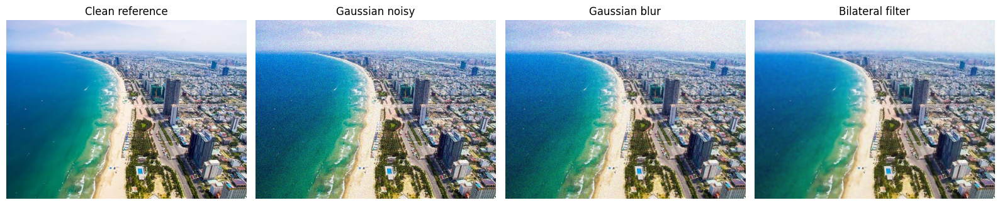

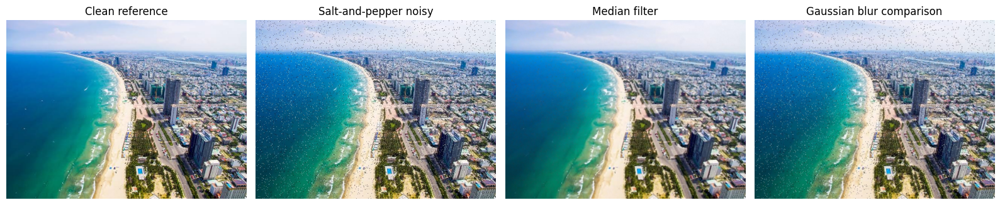

In [6]:
show_images(
    [clean, gaussian_noisy, gaussian_blur, gaussian_bilateral],
    [
        "Clean reference",
        "Gaussian noisy",
        "Gaussian blur",
        "Bilateral filter",
    ],
    cols=4,
    figsize=(16, 5),
    save_path=OUT_DIR / "q1_gaussian_denoising_comparison.png",
)

show_images(
    [clean, saltpepper_noisy, sp_median, sp_gaussian_for_compare],
    [
        "Clean reference",
        "Salt-and-pepper noisy",
        "Median filter",
        "Gaussian blur comparison",
    ],
    cols=4,
    figsize=(16, 5),
    save_path=OUT_DIR / "q1_saltpepper_denoising_comparison.png",
)

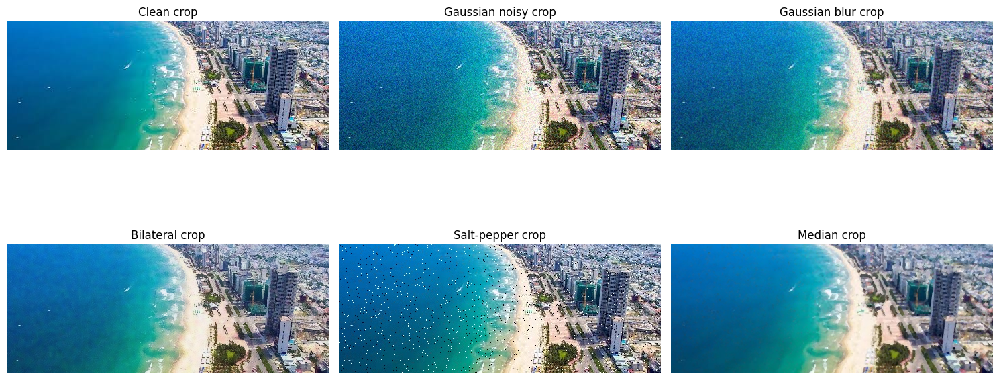

In [7]:
# Edge/detail crop for discussion. This middle-left crop usually includes beach/shore/building/tree-line edges.
h, w = clean.shape[:2]
y1, y2 = int(0.25 * h), int(0.65 * h)
x1, x2 = int(0.05 * w), int(0.80 * w)

crop_images = [
    clean[y1:y2, x1:x2],
    gaussian_noisy[y1:y2, x1:x2],
    gaussian_blur[y1:y2, x1:x2],
    gaussian_bilateral[y1:y2, x1:x2],
    saltpepper_noisy[y1:y2, x1:x2],
    sp_median[y1:y2, x1:x2],
]
crop_titles = [
    "Clean crop",
    "Gaussian noisy crop",
    "Gaussian blur crop",
    "Bilateral crop",
    "Salt-pepper crop",
    "Median crop",
]

show_images(
    crop_images,
    crop_titles,
    cols=3,
    figsize=(15, 8),
    save_path=OUT_DIR / "q1_edge_crop_comparison.png",
)

**Discussion.** Increasing smoothing strength removes more random variation, but it also removes high-frequency details. In the crop, the shoreline/tree/building boundaries are the important edges. A Gaussian blur reduces Gaussian grain, but it averages across both sides of an edge, so boundaries become softer. The bilateral filter gives the best structural result for the Gaussian-noisy image here because it averages nearby pixels with similar color while reducing averaging across strong edges. For salt-and-pepper noise, the median filter is more appropriate than Gaussian blur because isolated black/white impulses are outliers; replacing a pixel by the local median removes those impulses while preserving step edges better than linear averaging.

## Question 2 - Feature Matching and Multi-View Alignment

I use SIFT when available because it is more robust to scale, rotation, and illumination changes than simple corner descriptors. If SIFT is unavailable, the code falls back to ORB. CLAHE is applied to grayscale images before feature extraction to reduce lighting differences between day, sunset, and rainy views.

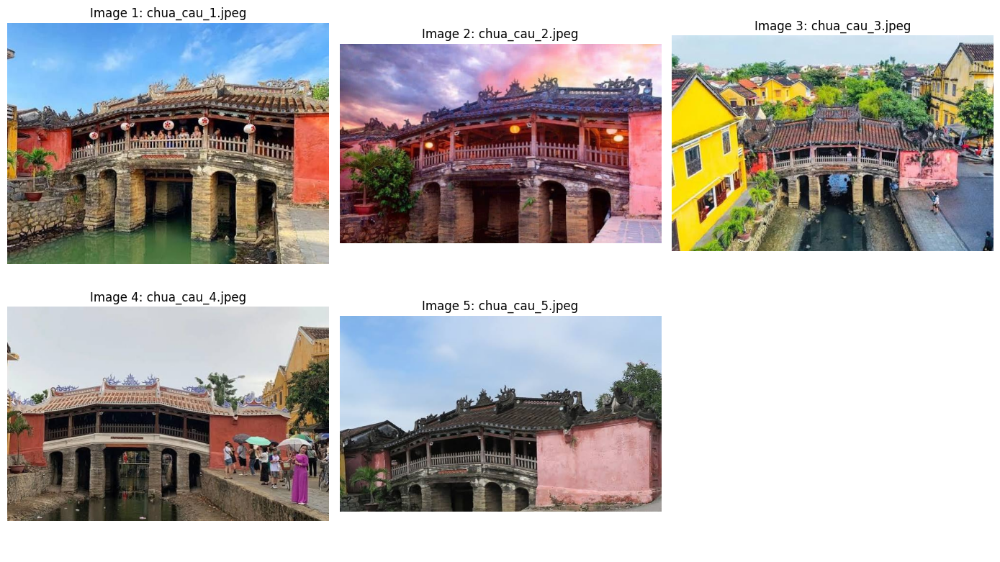

In [8]:
q2_dir = DATA_DIR / "q2_bridge_views"

def image_id(path):
    return path.stem.split("_")[-1]

q2_paths = sorted(q2_dir.glob("chua_cau_*.jpeg"), key=lambda p: int(image_id(p)))
bridge_labels = [image_id(p) for p in q2_paths]
bridge_images = {image_id(p): imread_rgb(p) for p in q2_paths}

show_images(
    [bridge_images[label] for label in bridge_labels],
    [f"Image {label}: {Path(q2_paths[i]).name}" for i, label in enumerate(bridge_labels)],
    cols=3,
    figsize=(14, 8),
    save_path=OUT_DIR / "q2_input_views.png",
)

In [9]:
if hasattr(cv2, "SIFT_create"):
    DETECTOR_NAME = "SIFT"
    detector = cv2.SIFT_create(nfeatures=5000)
    norm_type = cv2.NORM_L2
    LOWE_RATIO = 0.70
else:
    DETECTOR_NAME = "ORB"
    detector = cv2.ORB_create(nfeatures=5000, fastThreshold=7)
    norm_type = cv2.NORM_HAMMING
    LOWE_RATIO = 0.75

RANSAC_REPROJ_THRESHOLD = 5.0
MIN_INLIERS = 8

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_for_features(img_rgb):
    gray = to_gray(img_rgb)
    return clahe.apply(gray)

features = {}
feature_rows = []
for label in bridge_labels:
    gray = preprocess_for_features(bridge_images[label])
    keypoints, descriptors = detector.detectAndCompute(gray, None)
    features[label] = {
        "gray": gray,
        "keypoints": keypoints,
        "descriptors": descriptors,
    }
    feature_rows.append(
        {
            "image": label,
            "file": f"chua_cau_{label}.jpeg",
            "detector": DETECTOR_NAME,
            "keypoints": len(keypoints),
        }
    )

print(f"Detector: {DETECTOR_NAME}, Lowe ratio: {LOWE_RATIO}, RANSAC threshold: {RANSAC_REPROJ_THRESHOLD}px")
print(f"Minimum inliers for a reported homography: {MIN_INLIERS}")
display(pd.DataFrame(feature_rows))

Detector: SIFT, Lowe ratio: 0.7, RANSAC threshold: 5.0px
Minimum inliers for a reported homography: 8


,image,file,detector,keypoints
0,1,chua_cau_1.jpeg,SIFT,2677
1,2,chua_cau_2.jpeg,SIFT,3723
2,3,chua_cau_3.jpeg,SIFT,3097
3,4,chua_cau_4.jpeg,SIFT,3398
4,5,chua_cau_5.jpeg,SIFT,2432


**Homography threshold.** A homography mathematically needs four point correspondences, but four matches are too fragile in a real image pair. I use `MIN_INLIERS = 8`, roughly double the mathematical minimum, so that a homography is only marked valid when RANSAC finds a small but meaningful consensus set. The RANSAC reprojection threshold is `5 px`, allowing minor localization error while still rejecting large outliers.

In [10]:
matcher = cv2.BFMatcher(norm_type)

pair_results = {}
rows = []

for label_a, label_b in itertools.combinations(bridge_labels, 2):
    kp_a = features[label_a]["keypoints"]
    kp_b = features[label_b]["keypoints"]
    des_a = features[label_a]["descriptors"]
    des_b = features[label_b]["descriptors"]

    if des_a is None or des_b is None or len(des_a) < 2 or len(des_b) < 2:
        knn_matches = []
    else:
        knn_matches = matcher.knnMatch(des_a, des_b, k=2)

    good_matches = []
    first_matches = []
    for candidate in knn_matches:
        if len(candidate) == 0:
            continue
        first_matches.append(candidate[0])
        if len(candidate) < 2:
            continue
        m, n = candidate
        if m.distance < LOWE_RATIO * n.distance:
            good_matches.append(m)

    first_matches = sorted(first_matches, key=lambda m: m.distance)

    H = None
    mask = None
    inlier_count = 0
    inlier_ratio = 0.0

    if len(good_matches) >= 4:
        pts_a = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        pts_b = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        H, mask = cv2.findHomography(pts_a, pts_b, cv2.RANSAC, RANSAC_REPROJ_THRESHOLD)
        if mask is not None:
            mask = mask.ravel().astype(bool)
            inlier_count = int(mask.sum())
            inlier_ratio = inlier_count / max(len(good_matches), 1)

    homography_valid = H is not None and inlier_count >= MIN_INLIERS
    pair_results[(label_a, label_b)] = {
        "good_matches": good_matches,
        "first_matches": first_matches,
        "H": H,
        "mask": mask,
        "inliers": inlier_count,
        "inlier_ratio": inlier_ratio,
        "homography_valid": homography_valid,
    }

    rows.append(
        {
            "pair": f"{label_a}-{label_b}",
            "image_a": label_a,
            "image_b": label_b,
            "good_matches": len(good_matches),
            "inliers": inlier_count,
            "inlier_ratio": inlier_ratio,
            "homography_valid": homography_valid,
        }
    )

q2_results_df = pd.DataFrame(rows)
q2_results_df.to_csv(OUT_DIR / "q2_pair_matching_results.csv", index=False)
display(q2_results_df.sort_values("inliers", ascending=False).round(3))

,pair,image_a,image_b,good_matches,inliers,inlier_ratio,homography_valid
3,1-5,1,5,37,27,0.730,True
6,2-5,2,5,31,18,0.581,True
0,1-2,1,2,24,16,0.667,True
5,2-4,2,4,19,9,0.474,True
9,4-5,4,5,21,8,0.381,True
2,1-4,1,4,12,8,0.667,True
7,3-4,3,4,15,6,0.400,False
4,2-3,2,3,10,4,0.400,False
8,3-5,3,5,8,4,0.500,False
1,1-3,1,3,3,0,0.000,False


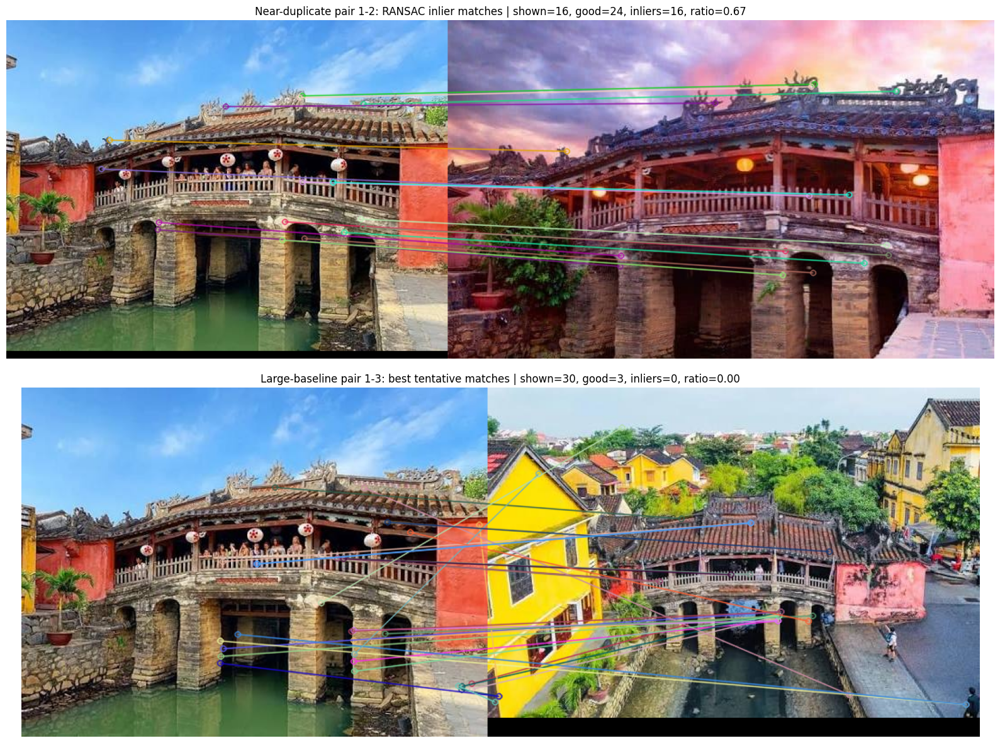

In [11]:
def get_pair_key(label_a, label_b):
    if (label_a, label_b) in pair_results:
        return (label_a, label_b), False
    if (label_b, label_a) in pair_results:
        return (label_b, label_a), True
    raise KeyError((label_a, label_b))

def matches_for_display(label_a, label_b, prefer_inliers=True, max_matches=30):
    pair_key, swapped = get_pair_key(label_a, label_b)
    result = pair_results[pair_key]

    key_a, key_b = pair_key
    kp_a = features[key_a]["keypoints"]
    kp_b = features[key_b]["keypoints"]
    img_a = bridge_images[key_a]
    img_b = bridge_images[key_b]

    if prefer_inliers and result["mask"] is not None and result["inliers"] > 0:
        matches = [m for m, keep in zip(result["good_matches"], result["mask"]) if keep]
    else:
        matches = result["good_matches"]
        if len(matches) < 8:
            matches = result["first_matches"]

    matches = sorted(matches, key=lambda m: m.distance)[:max_matches]

    if swapped:
        # This notebook only calls stored order pairs, but keep this branch for completeness.
        raise NotImplementedError("Display requested in swapped order; request stored pair order instead.")

    drawn = cv2.drawMatches(
        img_a,
        kp_a,
        img_b,
        kp_b,
        matches,
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    return drawn, len(matches), result

display_specs = [
    ("1", "2", True, "Near-duplicate pair 1-2: RANSAC inlier matches"),
    ("1", "3", False, "Large-baseline pair 1-3: best tentative matches"),
]

fig, axes = plt.subplots(2, 1, figsize=(16, 12))
for ax, (a, b, prefer_inliers, title) in zip(axes, display_specs):
    drawn, shown_count, result = matches_for_display(a, b, prefer_inliers=prefer_inliers, max_matches=30)
    ax.imshow(drawn)
    ax.set_title(
        f"{title} | shown={shown_count}, good={len(result['good_matches'])}, "
        f"inliers={result['inliers']}, ratio={result['inlier_ratio']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
fig.savefig(OUT_DIR / "q2_match_visualizations.png", dpi=160, bbox_inches="tight")
plt.show()

Inlier-count similarity matrix (diagonal ignored):


,1,2,3,4,5
1,0,16,0,8,27
2,16,0,4,9,18
3,0,4,0,6,4
4,8,9,6,0,8
5,27,18,4,8,0


Inlier-ratio similarity matrix (diagonal = 1.0 self-similarity):


,1,2,3,4,5
1,1.000,0.667,0.0,0.667,0.730
2,0.667,1.000,0.4,0.474,0.581
3,0.000,0.400,1.0,0.400,0.500
4,0.667,0.474,0.4,1.000,0.381
5,0.730,0.581,0.5,0.381,1.000


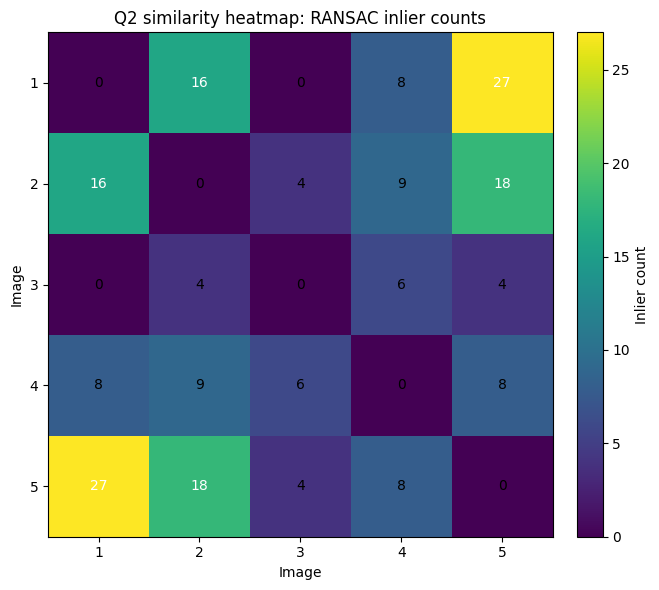

In [12]:
count_matrix = pd.DataFrame(0, index=bridge_labels, columns=bridge_labels, dtype=int)
ratio_matrix = pd.DataFrame(np.eye(len(bridge_labels)), index=bridge_labels, columns=bridge_labels, dtype=float)

for _, row in q2_results_df.iterrows():
    a, b = row["image_a"], row["image_b"]
    count_matrix.loc[a, b] = count_matrix.loc[b, a] = int(row["inliers"])
    ratio_matrix.loc[a, b] = ratio_matrix.loc[b, a] = float(row["inlier_ratio"])

print("Inlier-count similarity matrix (diagonal ignored):")
display(count_matrix)

print("Inlier-ratio similarity matrix (diagonal = 1.0 self-similarity):")
display(ratio_matrix.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
values = count_matrix.values.astype(float)
im = ax.imshow(values, cmap="viridis")
ax.set_xticks(range(len(bridge_labels)), bridge_labels)
ax.set_yticks(range(len(bridge_labels)), bridge_labels)
ax.set_xlabel("Image")
ax.set_ylabel("Image")
ax.set_title("Q2 similarity heatmap: RANSAC inlier counts")
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        color = "white" if values[i, j] > values.max() * 0.45 else "black"
        ax.text(j, i, int(values[i, j]), ha="center", va="center", color=color)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Inlier count")
plt.tight_layout()
fig.savefig(OUT_DIR / "q2_similarity_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

In [13]:
ranked_pairs = q2_results_df.sort_values(["inliers", "inlier_ratio"], ascending=False).reset_index(drop=True)
weakest_pairs = q2_results_df.sort_values(["inliers", "inlier_ratio"], ascending=True).reset_index(drop=True)

print("Most similar pair by inlier count:")
display(ranked_pairs.head(3).round(3))

print("Most different pairs by inlier count/ratio:")
display(weakest_pairs.head(3).round(3))

print("Pairs involving image 3:")
display(q2_results_df[(q2_results_df["image_a"] == "3") | (q2_results_df["image_b"] == "3")].round(3))

Most similar pair by inlier count:


,pair,image_a,image_b,good_matches,inliers,inlier_ratio,homography_valid
0,1-5,1,5,37,27,0.730,True
1,2-5,2,5,31,18,0.581,True
2,1-2,1,2,24,16,0.667,True


Most different pairs by inlier count/ratio:


,pair,image_a,image_b,good_matches,inliers,inlier_ratio,homography_valid
0,1-3,1,3,3,0,0.0,False
1,2-3,2,3,10,4,0.4,False
2,3-5,3,5,8,4,0.5,False


Pairs involving image 3:


,pair,image_a,image_b,good_matches,inliers,inlier_ratio,homography_valid
1,1-3,1,3,3,0,0.0,False
4,2-3,2,3,10,4,0.4,False
7,3-4,3,4,15,6,0.4,False
8,3-5,3,5,8,4,0.5,False


**Relative viewpoint analysis.** The inlier matrix is the practical similarity measure: more RANSAC inliers mean more geometrically consistent local features between two views. Images `1`, `2`, and `4` are expected to score relatively well because they are close to a frontal view of the same bridge. Lighting differs, but SIFT mainly uses local gradient structure, so roof edges, windows, signs, and high-contrast architectural boundaries can still match after grayscale/CLAHE preprocessing.

Pairs involving image `3` are expected to score lower because image `3` is an elevated/oblique wider-context view. The camera position changes the visible surfaces and introduces stronger perspective/parallax, so a single 2D homography is a weaker model and many tentative matches become RANSAC outliers. Image `5` is also a larger-baseline side/three-quarter view, but in this run it still shares enough bridge facade/roof texture with some frontal images to produce a strong match. This is a useful reminder that feature similarity depends on actual visible overlap as well as the nominal viewpoint label.

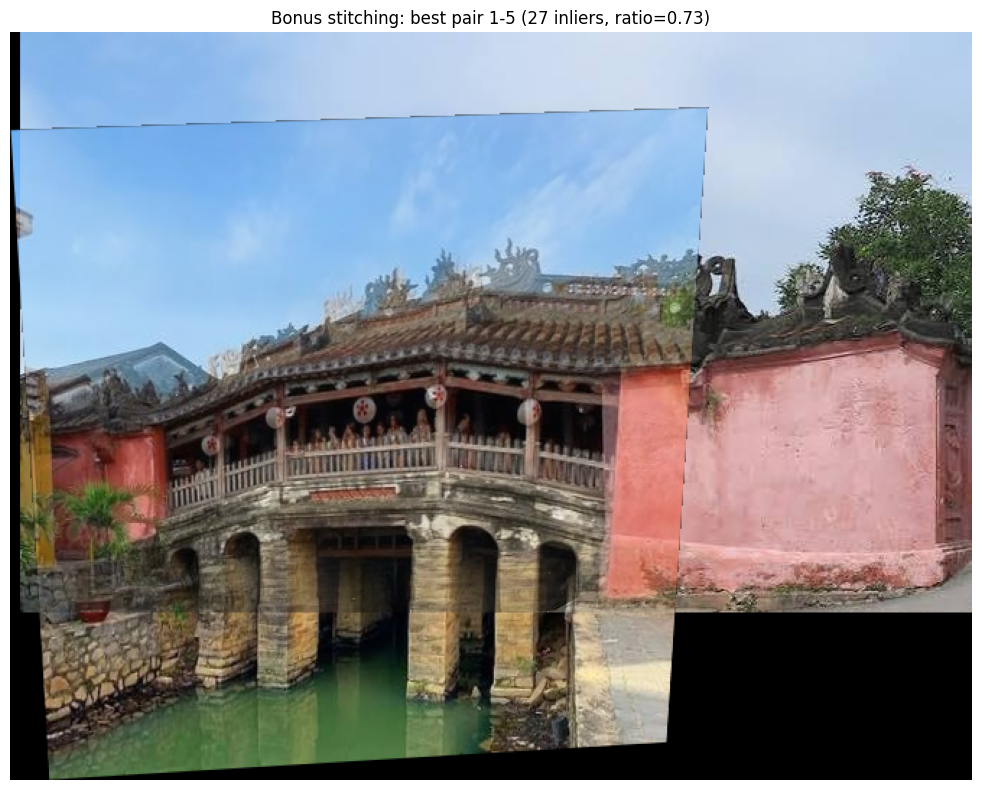

In [14]:
def stitch_with_homography(label_a, label_b):
    pair_key, swapped = get_pair_key(label_a, label_b)
    if swapped:
        raise NotImplementedError("Stitching expects stored pair order.")

    result = pair_results[pair_key]
    H = result["H"]
    if H is None:
        raise ValueError(f"No homography for pair {label_a}-{label_b}")

    img_a = bridge_images[label_a]
    img_b = bridge_images[label_b]
    h_a, w_a = img_a.shape[:2]
    h_b, w_b = img_b.shape[:2]

    corners_a = np.float32([[0, 0], [w_a, 0], [w_a, h_a], [0, h_a]]).reshape(-1, 1, 2)
    corners_b = np.float32([[0, 0], [w_b, 0], [w_b, h_b], [0, h_b]]).reshape(-1, 1, 2)
    warped_corners_a = cv2.perspectiveTransform(corners_a, H)

    all_corners = np.concatenate([warped_corners_a, corners_b], axis=0)
    xmin, ymin = np.floor(all_corners.min(axis=0).ravel()).astype(int)
    xmax, ymax = np.ceil(all_corners.max(axis=0).ravel()).astype(int)

    translation = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1]], dtype=np.float64)
    width = int(xmax - xmin)
    height = int(ymax - ymin)

    warped_a = cv2.warpPerspective(img_a, translation @ H, (width, height))
    canvas_b = np.zeros_like(warped_a)
    x_offset, y_offset = -xmin, -ymin
    canvas_b[y_offset:y_offset + h_b, x_offset:x_offset + w_b] = img_b

    mask_a = warped_a.sum(axis=2) > 0
    mask_b = canvas_b.sum(axis=2) > 0

    composite = np.zeros_like(warped_a)
    only_a = mask_a & ~mask_b
    only_b = mask_b & ~mask_a
    overlap = mask_a & mask_b
    composite[only_a] = warped_a[only_a]
    composite[only_b] = canvas_b[only_b]
    composite[overlap] = (
        0.5 * warped_a[overlap].astype(np.float32) + 0.5 * canvas_b[overlap].astype(np.float32)
    ).astype(np.uint8)

    return composite

valid_pairs = q2_results_df[q2_results_df["homography_valid"]].sort_values("inliers", ascending=False)
if valid_pairs.empty:
    print("No pair reached the minimum inlier threshold for stitching.")
else:
    best = valid_pairs.iloc[0]
    best_a, best_b = best["image_a"], best["image_b"]
    stitched = stitch_with_homography(best_a, best_b)
    save_rgb(OUT_DIR / "q2_stitch_best_pair.png", stitched)

    plt.figure(figsize=(14, 8))
    plt.imshow(stitched)
    plt.title(
        f"Bonus stitching: best pair {best_a}-{best_b} "
        f"({int(best['inliers'])} inliers, ratio={best['inlier_ratio']:.2f})"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "q2_stitch_best_pair_figure.png", dpi=160, bbox_inches="tight")
    plt.show()

**Bonus stitching note.** The composite uses the homography from the highest-inlier pair and simple averaging in overlap regions. It is enough to demonstrate feature-based alignment, but visible seams or ghosting can remain because the bridge photos are not a perfect panorama sequence and some pairs have viewpoint/parallax differences.